# Customer Churn Predictor
**Goal:** find out *why* telecom customers leave, build a model that predicts *who will leave next*, and turn the result into business actions.

**Data:** Telco Customer Churn (7,043 customers, 21 columns). Each row is one customer. The last column, `Churn`, says if they left (Yes) or stayed (No).

> Running in Google Colab? Upload `telco_churn.csv` first (folder icon on the left, then the upload button).

## Step 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("telco_churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Step 2. First look
Before changing anything, check the size, the column types, duplicates and missing values.

In [2]:
print("Rows and columns:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Missing values (NaN):", df.isna().sum().sum())
print()
df.info()

Rows and columns: (7043, 21)
Duplicate rows: 0
Missing values (NaN): 0

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-n

In [3]:
# How many customers left? (the column we want to predict)
print(df["Churn"].value_counts())
print()
print((df["Churn"].value_counts(normalize=True) * 100).round(1))

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


**What I see:**
- 7,043 rows and 21 columns, no duplicate rows and no NaN cells.
- `TotalCharges` shows as text (`object`), but it should be a number. That is a problem to fix.
- Only about **26.5%** of customers churned. The classes are *imbalanced*: far more "No" than "Yes". This matters later, because a lazy model could just say "No" for everyone and still look 73% accurate.

## Step 3. Clean the data

In [4]:
# TotalCharges is text. Try to turn it into numbers. Blank cells become NaN.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Blank TotalCharges:", df["TotalCharges"].isna().sum())

# Who are these 11 customers?
df[df["TotalCharges"].isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


All 11 have `tenure = 0`. They just joined and have not been billed yet, so their total is really **0**. I fill the blanks with 0 instead of deleting the rows.

In [5]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# customerID is just a label. It tells the model nothing, so drop it.
df = df.drop(columns="customerID")

print("Blank TotalCharges now:", df["TotalCharges"].isna().sum())
print("TotalCharges type:", df["TotalCharges"].dtype)

Blank TotalCharges now: 0
TotalCharges type: float64


## Step 4. Explore: why do customers leave?
A small helper function draws the churn rate (% who left) for any column.

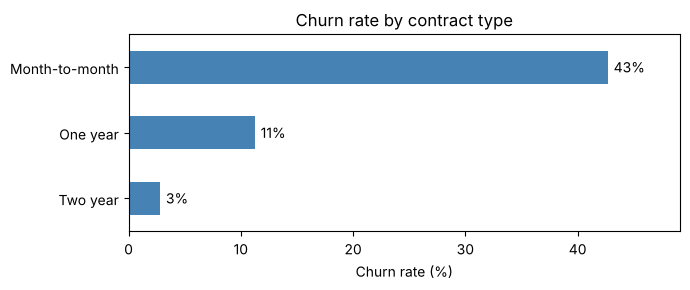

Contract
Two year           2.8
One year          11.3
Month-to-month    42.7
Name: Churn, dtype: float64

In [6]:
def churn_rate_plot(column, title):
    # % of customers who churned in each group
    rate = df.groupby(column)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
    rate = rate.sort_values()
    ax = rate.plot(kind="barh", color="steelblue", figsize=(7, 3))
    ax.set_xlabel("Churn rate (%)")
    ax.set_ylabel("")
    ax.set_title(title)
    for i, v in enumerate(rate):
        ax.text(v + 0.5, i, f"{v:.0f}%", va="center")
    ax.set_xlim(0, rate.max() * 1.15)
    plt.tight_layout()
    plt.show()
    return rate.round(1)

churn_rate_plot("Contract", "Churn rate by contract type")

**Contract is the biggest signal.** Month-to-month customers churn at about **43%**, one-year at **11%**, and two-year at only **3%**. People on month-to-month plans can leave whenever they like.

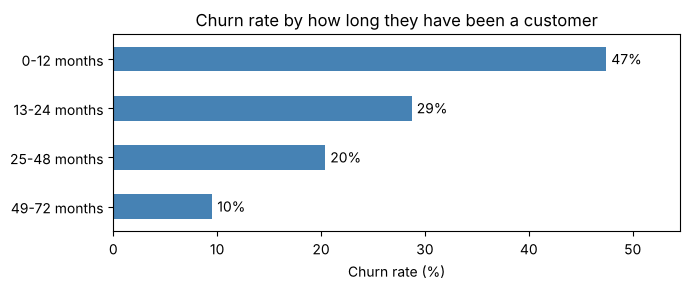

TenureGroup
49-72 months     9.5
25-48 months    20.4
13-24 months    28.7
0-12 months     47.4
Name: Churn, dtype: float64

In [7]:
# Group tenure (months with the company) into bands
df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                           labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"])
churn_rate_plot("TenureGroup", "Churn rate by how long they have been a customer")

**Most churn happens early.** Almost **47%** of customers in their first year leave, falling to under 10% for customers who stayed more than four years.

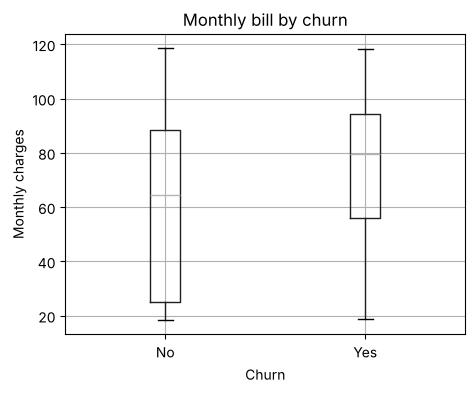

Churn
No     61.3
Yes    74.4
Name: MonthlyCharges, dtype: float64


In [8]:
# Monthly bill: do churners pay more?
df.boxplot(column="MonthlyCharges", by="Churn", figsize=(5, 4))
plt.title("Monthly bill by churn")
plt.suptitle("")
plt.ylabel("Monthly charges")
plt.show()

print(df.groupby("Churn")["MonthlyCharges"].mean().round(1))

Customers who left pay more per month on average (about **74** vs **61**). Higher bills make people look for a cheaper option.

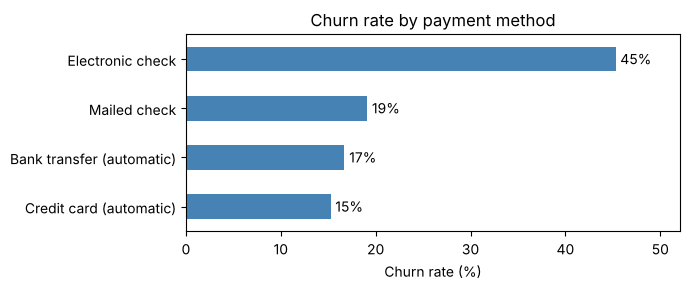

PaymentMethod
Credit card (automatic)      15.2
Bank transfer (automatic)    16.7
Mailed check                 19.1
Electronic check             45.3
Name: Churn, dtype: float64

In [9]:
churn_rate_plot("PaymentMethod", "Churn rate by payment method")

**Electronic check users churn at about 45%**, roughly three times the rate of customers on automatic payment (15 to 17%). Automatic payment may be a sign of commitment, or it may just make leaving less likely by habit.

A few more columns that often matter:

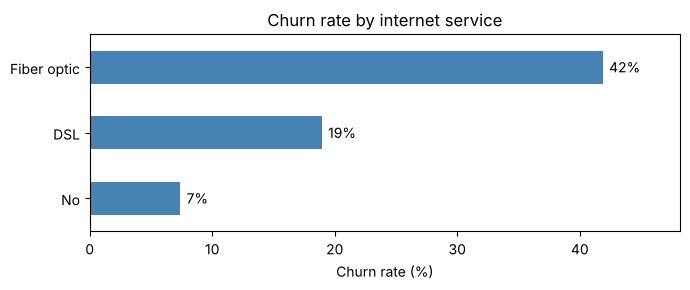

InternetService
No              7.4
DSL            19.0
Fiber optic    41.9
Name: Churn, dtype: float64

In [10]:
churn_rate_plot("InternetService", "Churn rate by internet service")

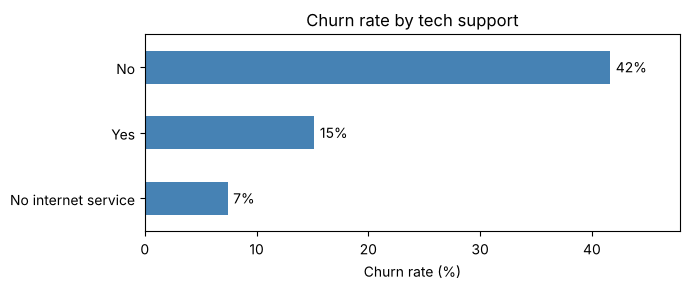

TechSupport
No internet service     7.4
Yes                    15.2
No                     41.6
Name: Churn, dtype: float64

In [11]:
churn_rate_plot("TechSupport", "Churn rate by tech support")

- **Fibre optic** customers churn at about **42%**, versus 19% for DSL. Fibre is the more expensive plan, so price or service quality may be the cause.
- Customers **without tech support** churn at about **42%**, versus 15% for those with it. (The same pattern appears for online security.)

*Careful:* these charts show that things happen *together*. They do not prove one thing *causes* the other.

## Step 5. Prepare the data for the model

In [12]:
# X = the clues (all columns except the answer), y = the answer we want to predict (1 = churned)
X = df.drop(columns=["Churn", "TenureGroup"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# Split 80% to train, 20% to test.
# stratify=y keeps the same % of churners in both parts.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Churn % in train:", round(y_train.mean() * 100, 1))
print("Churn % in test: ", round(y_test.mean() * 100, 1))

Train rows: 5634 | Test rows: 1409
Churn % in train: 26.5
Churn % in test:  26.5


Both parts keep the ratio of about 26.5% churners, so the test is fair.

## Step 6. Build a pipeline
A pipeline bundles the preparation steps and the model together, so the **exact same steps** are applied to training data, test data and new customers in the app.

- Numbers (`tenure`, `MonthlyCharges`, `TotalCharges`) are **scaled** so they are on a similar range.
- Text categories (like `Contract`) are **one-hot encoded**: each category becomes its own 0/1 column.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

number_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
category_cols = [c for c in X.columns if c not in number_cols]

preprocess = ColumnTransformer([
    ("numbers", StandardScaler(), number_cols),
    ("categories", OneHotEncoder(handle_unknown="ignore"), category_cols),
])

print("Number columns:", number_cols)
print("Category columns:", len(category_cols))

Number columns: ['tenure', 'MonthlyCharges', 'TotalCharges']
Category columns: 16


## Step 7. Compare three models
I train **Logistic Regression**, **Decision Tree** and **Random Forest**, and measure them on the test set.

The metric that matters most is **recall**: out of all customers who really left, how many did the model catch? A missed churner is a lost customer.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score

def compare_models(class_weight):
    models = {
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight=class_weight),
        "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42, class_weight=class_weight),
        "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, class_weight=class_weight),
    }
    rows = []
    for name, model in models.items():
        pipe = Pipeline([("prep", preprocess), ("model", model)])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        rows.append({"Model": name,
                     "Accuracy": accuracy_score(y_test, pred),
                     "Recall": recall_score(y_test, pred),
                     "Precision": precision_score(y_test, pred)})
    return pd.DataFrame(rows).set_index("Model").round(3)

plain = compare_models(None)
plain

,Accuracy,Recall,Precision
Model,,,
Logistic Regression,0.806,0.559,0.657
Decision Tree,0.798,0.567,0.635
Random Forest,0.783,0.481,0.616


Without any help, every model **misses about half of the churners** (recall 48 to 57%). Accuracy looks fine at around 78 to 81%, which is exactly the trap with imbalanced data.

## Step 8. Focus on recall: `class_weight="balanced"`
This option tells the model that a mistake on a churner costs more than a mistake on a loyal customer.

In [15]:
balanced = compare_models("balanced")
balanced

,Accuracy,Recall,Precision
Model,,,
Logistic Regression,0.738,0.783,0.504
Decision Tree,0.754,0.757,0.526
Random Forest,0.764,0.623,0.548


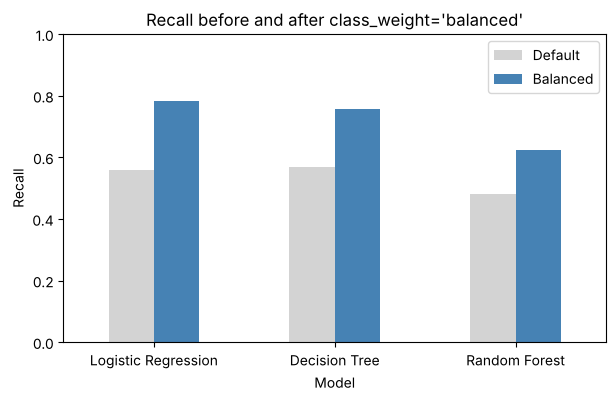

In [16]:
# Side-by-side recall chart
both = pd.DataFrame({"Default": plain["Recall"], "Balanced": balanced["Recall"]})
ax = both.plot(kind="bar", figsize=(7, 4), color=["lightgray", "steelblue"], rot=0)
ax.set_ylabel("Recall")
ax.set_title("Recall before and after class_weight='balanced'")
ax.set_ylim(0, 1)
plt.show()

Balancing lifts recall a lot for every model. **Logistic Regression (balanced) is the best at about 78%**, ahead of the balanced Decision Tree (76%) and Random Forest (62%).

The price: **precision drops** (to about 50%), so roughly half of the customers it flags will not actually leave. That is acceptable here, because contacting a loyal customer with an offer costs far less than losing a customer.

## Step 9. Tune the best model with GridSearchCV
I try several values of `C` (how strongly the model is held back from over-fitting) and score each with 5-fold cross-validation, using **recall** as the goal.

In [17]:
from sklearn.model_selection import GridSearchCV

best_pipe = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

grid = GridSearchCV(best_pipe,
                    param_grid={"model__C": [0.01, 0.05, 0.1, 0.5, 1, 5, 10]},
                    scoring="recall", cv=5)
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print("Best cross-validated recall:", round(grid.best_score_, 3))

Best settings: {'model__C': 1}
Best cross-validated recall: 0.805


The search picks `C = 1`, which is the default value. So the model was already well set up, and tuning gave **no extra gain**. That is a real result too: it shows the simple model is not leaving easy performance on the table.

## Step 10. Evaluate on the unseen test data

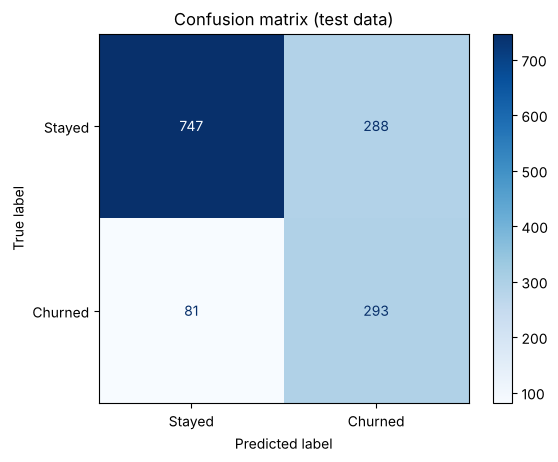

              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [18]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

final_model = grid.best_estimator_
pred = final_model.predict(X_test)

ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=["Stayed", "Churned"]).plot(cmap="Blues")
plt.title("Confusion matrix (test data)")
plt.show()

print(classification_report(y_test, pred, target_names=["Stayed", "Churned"]))

**How to read it (test set: 1,409 customers, 374 of them real churners):**
- The model **caught 293 of the 374** customers who left. That is a recall of **78%**.
- It **missed 81** churners.
- It raised **288 false alarms**: loyal customers flagged as risky. That is why precision is about 50%.
- Overall accuracy is 74%. That is lower than the "plain" models, and that is fine: we chose to catch more churners on purpose.

## Step 11. What drives the prediction?
In Logistic Regression each column gets a weight. Positive weights push towards *churn*, negative weights push towards *staying*.

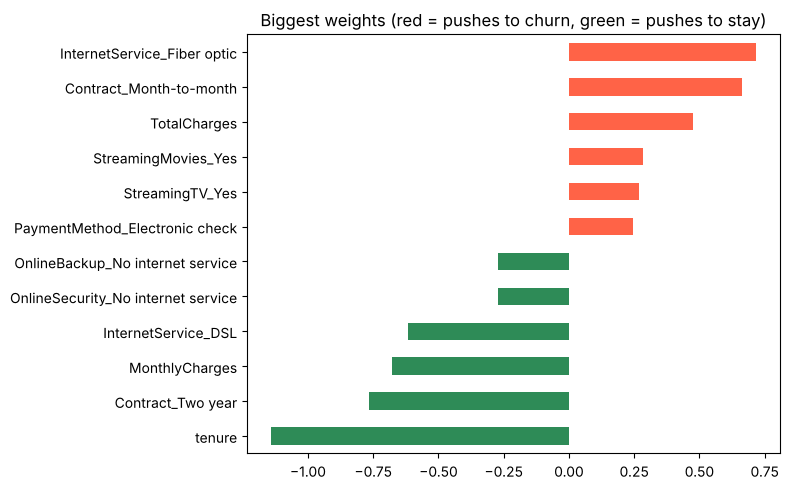

In [19]:
names = final_model.named_steps["prep"].get_feature_names_out()
weights = pd.Series(final_model.named_steps["model"].coef_[0], index=names)
weights.index = weights.index.str.replace("numbers__", "").str.replace("categories__", "")

top = pd.concat([weights.sort_values().head(6), weights.sort_values().tail(6)])
colors = ["tomato" if w > 0 else "seagreen" for w in top]
ax = top.plot(kind="barh", color=colors, figsize=(8, 5))
ax.set_title("Biggest weights (red = pushes to churn, green = pushes to stay)")
plt.tight_layout()
plt.show()

The model agrees with the charts: **short tenure, month-to-month contract and fibre optic internet** push towards churn, while **long tenure and a two-year contract** push towards staying.

## Step 12. Turn probabilities into High / Medium / Low risk
The model can give each customer a churn probability. For the app I turn that into three simple levels. Do they make sense on the test data?

In [20]:
prob = final_model.predict_proba(X_test)[:, 1]

risk = pd.cut(prob, bins=[0, 0.30, 0.60, 1.0], labels=["Low", "Medium", "High"])

check = pd.DataFrame({"Risk": risk, "Churned": y_test.values})
summary = check.groupby("Risk", observed=True)["Churned"].agg(["count", "mean"])
summary["mean"] = (summary["mean"] * 100).round(1)
summary.columns = ["Customers", "Actually churned (%)"]
summary

,Customers,Actually churned (%)
Risk,,
Low,601,4.5
Medium,319,26.0
High,489,54.0


The levels work: the share of customers who really left rises clearly from Low to Medium to High. The app uses the same cut-offs (below 30% = Low, 30 to 60% = Medium, 60% or more = High).

## Step 13. Business recommendations

1. **Move month-to-month customers onto longer contracts.** They churn at about 43%, against 11% (one year) and 3% (two years). Offer a small discount or a free add-on for switching to a 1 or 2-year plan.
2. **Protect the first year.** Around 47% of customers in their first 12 months leave. Add a welcome call, a check-in around month 2 or 3, and an early offer for anyone the model rates High risk.
3. **Look into fibre optic customers.** They churn at about 42% vs 19% for DSL and pay more. Check service quality and pricing, and bundle tech support or online security (customers without them churn at about 42%, with them about 15%) for new fibre customers.
4. **Move electronic-check payers to automatic payment.** They churn at about 45% vs 15 to 17% for automatic payers. A small bill credit for switching could help.
5. **Use the model as a weekly call list.** Score every customer, and send High-risk ones to the retention team first.

*Note:* the patterns above are links, not proven causes, so test each action on a small group before rolling it out.

## Step 14. Summary
- Cleaned `TotalCharges` and dropped `customerID`.
- Found that contract type, tenure, payment method and internet service explain most churn.
- Compared three models. **Logistic Regression with `class_weight="balanced"`** won on recall: **78%** of churners caught.
- The same pipeline powers the Streamlit app (`app.py`).